In [3]:
from pathlib import Path
import json
import pickle
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    
DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "data" / "reports"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for folder in [REPORT_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FEATURES = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate","Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]

TARGET = "Potability"
RANDOM_SEED = 42
print("Project folder:", PROJECT_ROOT)

Project folder: d:\sample_project\SC11-Water-Quality-Potability-Example


In [9]:
def load_split(name):
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {path}. Complete Step 2 first.")
    frame = pd.read_csv(path)
    required = FEATURES + [TARGET]
    if frame[required].isna().sum().sum() != 0:
        raise ValueError(f"{name}.csv still has missing values.")
    return frame

In [10]:

train_data = load_split("train")
validation_data = load_split("validation")
test_data = load_split("test")
for name, frame in [("Train", train_data), ("Validation", validation_data), ("Test", test_data)]:
    print(f"\n{name}: {frame.shape[0]} rows, {frame.shape[1]} columns")
    print(frame[TARGET].value_counts(normalize=True).round(3))
train_data.head()


Train: 1788 rows, 10 columns
Potability
1    0.5
0    0.5
Name: proportion, dtype: float64

Validation: 384 rows, 10 columns
Potability
1    0.5
0    0.5
Name: proportion, dtype: float64

Test: 384 rows, 10 columns
Potability
1    0.5
0    0.5
Name: proportion, dtype: float64


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.292142,174.480427,33991.651567,9.511792,259.164965,435.108017,16.293614,81.690104,4.466913,1
1,5.646083,219.342932,22455.695012,8.283758,386.038790,401.256292,16.650114,31.174039,3.938506,1
2,6.652824,187.946409,19155.727561,5.949622,345.358533,433.875209,20.523191,26.140863,3.661529,0
3,7.828740,176.727511,33337.109649,5.438776,286.992631,290.118613,5.871941,75.714425,5.199447,1
4,11.898078,228.132673,8296.550611,9.899637,346.649750,500.169210,15.486862,63.529460,3.024968,1


In [11]:
X_train, y_train = train_data[FEATURES], train_data[TARGET]
X_validation, y_validation = validation_data[FEATURES], validation_data[TARGET]
X_test, y_test = test_data[FEATURES], test_data[TARGET]
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1788, 9)
y_train shape: (1788,)


In [12]:
ann_model = Pipeline(
    steps=[
    ("scaler", StandardScaler()),
    (
        "ann", MLPClassifier(
            hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
            learning_rate_init=0.001, max_iter=400, early_stopping=True,validation_fraction=0.15, 
            n_iter_no_change=25,random_state=RANDOM_SEED,
            )
        ),
    ]
)
print("ANN architecture: 9 inputs -> 16 -> 8 -> 1 output")
ann_model

ANN architecture: 9 inputs -> 16 -> 8 -> 1 output


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ann', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(16, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",400
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' o

In [13]:
ann_model.fit(X_train, y_train)
trained_ann = ann_model.named_steps["ann"]
print("Training iterations completed:", trained_ann.n_iter_)
print("Final training loss:", round(trained_ann.loss_, 5))

Training iterations completed: 96
Final training loss: 0.58313


In [15]:
def metric_row(y_true, y_pred, split_name):
    return {
        "split": split_name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1_score": round(f1_score(y_true, y_pred, zero_division=0), 4)
        }

validation_predictions = ann_model.predict(X_validation)
validation_metrics = metric_row(y_validation, validation_predictions, "validation")
pd.DataFrame([validation_metrics])

,split,accuracy,precision,recall,f1_score
0,validation,0.5443,0.5415,0.5781,0.5592


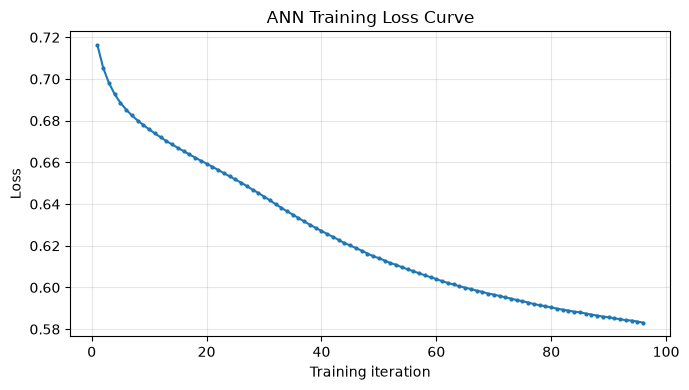

In [16]:
losses = trained_ann.loss_curve_
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(losses) + 1), losses, marker="o", markersize=2)
plt.title("ANN Training Loss Curve")
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "step3_ann_loss_curve.png", dpi=180)
plt.show()

In [17]:
def show_confusion_matrix(y_true, y_pred, split_name):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    figure, axis = plt.subplots(figsize=(5, 4))
    image = axis.imshow(matrix, cmap="Blues")
    figure.colorbar(image, ax=axis)
    axis.set(
        title=f"ANN Confusion Matrix - {split_name.title()} Split",
        xlabel="Predicted label", ylabel="Actual label",
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=["Not potable", "Potable"],
        yticklabels=["Not potable", "Potable"])

    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row, column], ha="center", va="center")
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / f"step3_{split_name}_confusion_matrix.png", dpi=180)
    plt.show()

,split,accuracy,precision,recall,f1_score
0,validation,0.5443,0.5415,0.5781,0.5592
1,test,0.6276,0.6310,0.6146,0.6227


Validation report:
               precision    recall  f1-score   support

           0       0.55      0.51      0.53       192
           1       0.54      0.58      0.56       192

    accuracy                           0.54       384
   macro avg       0.54      0.54      0.54       384
weighted avg       0.54      0.54      0.54       384

Test report:
               precision    recall  f1-score   support

           0       0.62      0.64      0.63       192
           1       0.63      0.61      0.62       192

    accuracy                           0.63       384
   macro avg       0.63      0.63      0.63       384
weighted avg       0.63      0.63      0.63       384



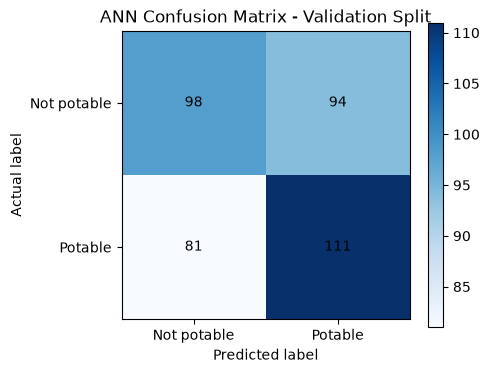

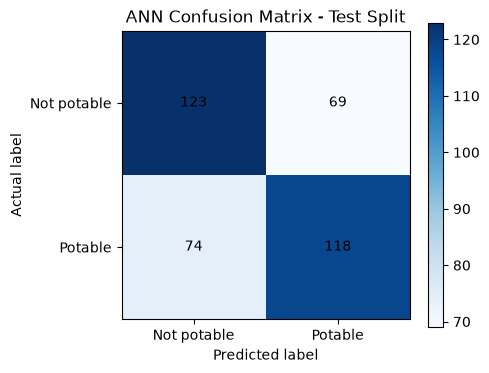

In [18]:
test_predictions = ann_model.predict(X_test)
test_metrics = metric_row(y_test, test_predictions, "test")
metrics = pd.DataFrame([validation_metrics, test_metrics])
display(metrics)
print("Validation report:\n", classification_report(y_validation, validation_predictions, zero_division=0))
print("Test report:\n", classification_report(y_test, test_predictions, zero_division=0))
show_confusion_matrix(y_validation, validation_predictions, "validation")
show_confusion_matrix(y_test, test_predictions, "test")

In [19]:
metrics.to_csv(REPORT_DIR / "step3_ann_metrics.csv", index=False)
for split_name, frame, predictions in [
    ("validation", validation_data, validation_predictions),
    ("test", test_data, test_predictions),
    ]:
    output = frame.copy()
    output["ann_prediction"] = predictions
    output["ann_potable_probability"] = ann_model.predict_proba(frame[FEATURES])[:, 1]
    output.to_csv(REPORT_DIR / f"step3_{split_name}_predictions.csv", index=False)

with (MODEL_DIR / "ann_water_potability.pkl").open("wb") as model_file:
    pickle.dump(ann_model, model_file)
metadata = {
    "technique": "Feed-forward ANN / backpropagation",
    "architecture": "9 inputs -> 16 -> 8 -> 1 output",
    "features": FEATURES, "target": TARGET, "random_seed": RANDOM_SEED
    }
(MODEL_DIR / "ann_model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved model and Step 3 evidence files.")

Saved model and Step 3 evidence files.
